# Moment of inertia: drone + box + payload

Uses the same pendulum method as Lab 3. **To use this notebook for a version:**
1. Set `RUN` below and run the notebook. If the folder doesn't exist yet, the notebook creates it with a copy of the box v1 config.
2. Edit `runs/<RUN>/config.json` with the masses, CG positions and pivot locations.
3. Record the swings from a terminal at the repo root (see below).
4. **Run All.**

In [1]:
RUN = 'box_v1'   # <-- the only thing you change: one folder per version

In [2]:
import shutil
from pathlib import Path
import numpy as np
from moi import analyze, load_config, combined_mass_and_cg, pivot_distance

run_dir = Path('runs') / RUN
if not (run_dir / 'config.json').exists():
    run_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy('runs/box_v1/config.json', run_dir / 'config.json')
    print(f'Created {run_dir}/config.json from box v1 - edit it, then rerun.')

missing = [a for a in 'xyz' if not (run_dir / f'{a}_data.json').exists()]
if missing:
    print('Still need to record:')
    for a in missing:
        print(f'  uv run python project-MOI/record.py project-MOI/runs/{RUN} {a}')
else:
    print(f'{run_dir}: all three swings recorded')

runs/box_v1: all three swings recorded


## Recording (terminal, repo root, drone on the rig)

```bash
uv run python project-MOI/record.py project-MOI/runs/<RUN> x   # push it when it says "Recording"
uv run python project-MOI/record.py project-MOI/runs/<RUN> y
uv run python project-MOI/record.py project-MOI/runs/<RUN> z
```
Add `--force` to redo an axis, or `--duration 20` to record for longer.

## Inputs

Body frame, in meters, with the origin at the bare drone's CG (+x forward, +y left, +z up). To change any of these, edit `config.json` and rerun.

In [3]:
cfg = load_config(run_dir)
print(cfg['description'], '\n')
print(f"{'part':<22}{'mass (g)':>10}   cg (mm)")
for p in cfg['parts']:
    print(f"{p['name']:<22}{1e3*p['mass']:>10.2f}   {np.round(1e3*p['cg'], 2)}")

masses = np.array([p['mass'] for p in cfg['parts']])
m, c = combined_mass_and_cg(masses, np.array([p['cg'] for p in cfg['parts']]))
print(f"\ntotal m = {1e3*m:.2f} g, combined CG = {np.round(1e3*c, 2)} mm")
for axis, a in cfg['axes'].items():
    print(f"{axis} rig: pivot {np.round(1e3*a['pivot'], 1)} mm  ->  r = {1e2*pivot_distance(c, a['pivot'], axis):.3f} cm"
          f"   (trim {a['t_min_offset']}s / {a['t_max_offset']}s)")

Box v1, empty (Task 5 empty configuration) 

part                    mass (g)   cg (mm)
drone                      32.00   [0. 0. 0.]
box_v1_empty                7.00   [  0.   0. -19.]

total m = 39.00 g, combined CG = [ 0.    0.   -3.41] mm
x rig: pivot [ 0. 29.  0.] mm  ->  r = 2.920 cm   (trim 1.0s / 0.0s)
y rig: pivot [29.  0.  0.] mm  ->  r = 2.920 cm   (trim 0.0s / 0.0s)
z rig: pivot [15.  0.  0.] mm  ->  r = 1.500 cm   (trim 3.3s / 0.0s)


## Analysis

For each axis, check that:
- the off-axis gyro traces stay small,
- every peak gets a dot and nothing else does,
- the period scatter is only a few samples (each sample is 10 ms).

If the start or end of a swing is junk, set `t_min_offset` / `t_max_offset` for that axis in `config.json` and rerun.

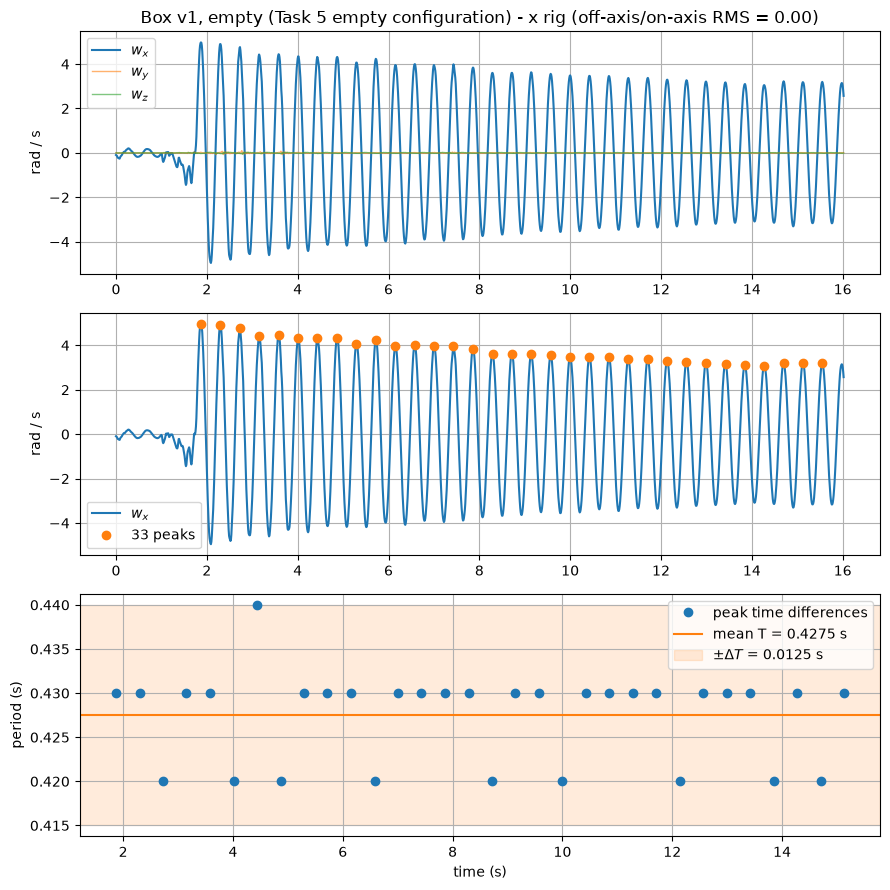

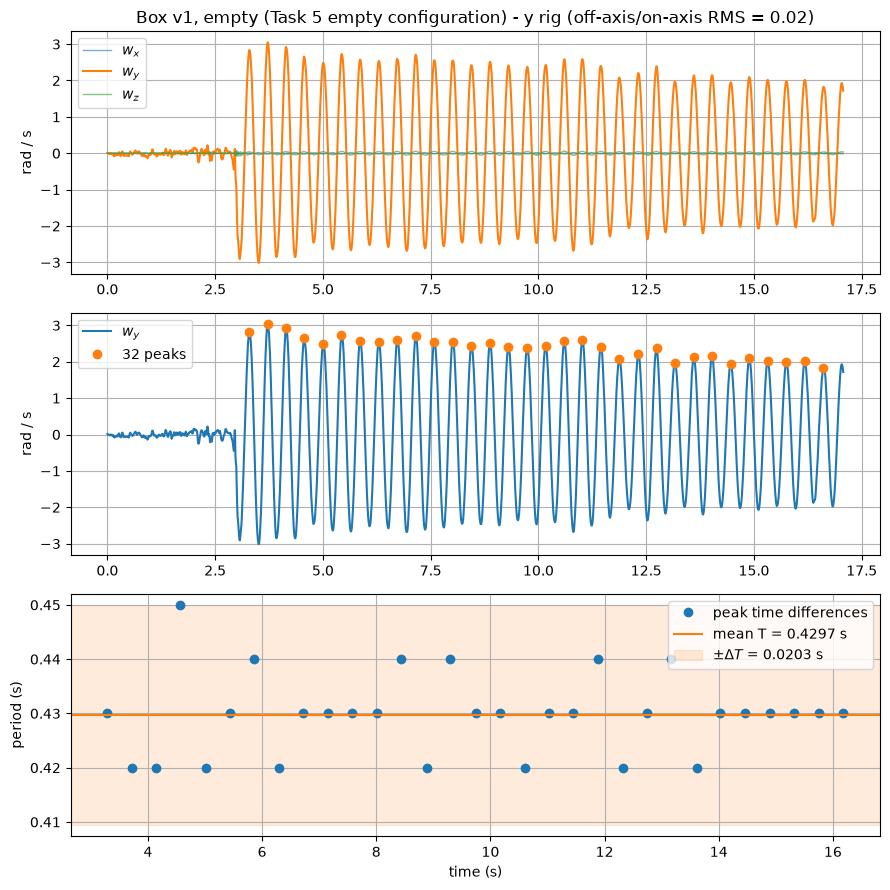

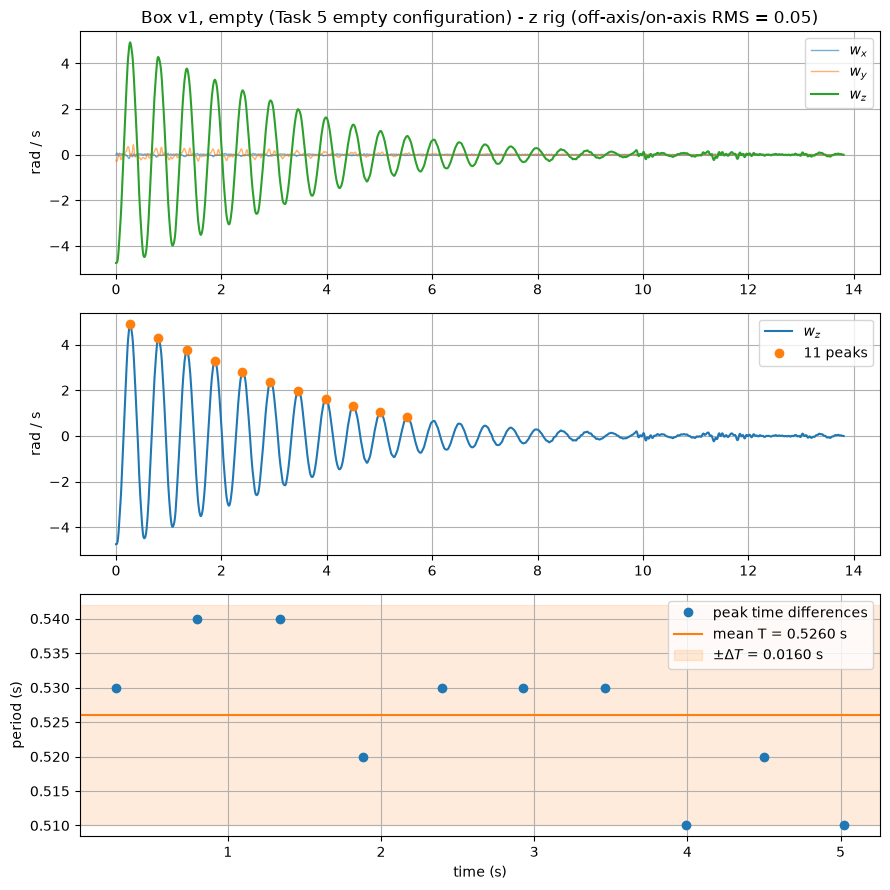


=== Box v1, empty (Task 5 empty configuration) ===
m   = 0.0390 +/- 0.0010 kg
CG shift from drone-alone CG = (0.00, 0.00, -3.41) mm

axis            T (s)           r (cm)             J (kg m^2)   largest dJ source
   x  0.4275 +/- 0.0125  2.920 +/- 0.204 1.846e-05 +/- 4.53e-06   T
   y  0.4297 +/- 0.0203  2.920 +/- 0.204 1.899e-05 +/- 6.42e-06   T
   z  0.5260 +/- 0.0160  1.500 +/- 0.200 3.144e-05 +/- 6.28e-06   pivot

Plots: x_check.png, y_check.png, z_check.png  |  results.json written


In [4]:
results = analyze(run_dir, show=True)

## Results

In [5]:
ax = results['axes']
print(f"m   = {results['m']:.4f} kg")
for k in 'xyz':
    if k in ax:
        print(f"J_{k} = {ax[k]['J']:.3e} +/- {ax[k]['delta_J']:.1e} kg m^2   ({100*ax[k]['delta_J']/ax[k]['J']:.0f}%)")

# Paste into the controller design notebook:
print('\n# ' + results['description'])
print(f"m = {results['m']:.4f}")
for k in 'xyz':
    if k in ax:
        print(f"J_{k} = {ax[k]['J']:.3e}")

m   = 0.0390 kg
J_x = 1.846e-05 +/- 4.5e-06 kg m^2   (25%)
J_y = 1.899e-05 +/- 6.4e-06 kg m^2   (34%)
J_z = 3.144e-05 +/- 6.3e-06 kg m^2   (20%)

# Box v1, empty (Task 5 empty configuration)
m = 0.0390
J_x = 1.846e-05
J_y = 1.899e-05
J_z = 3.144e-05
